In this this notebook, we explore when and why the primary bispectrum bias changes sign. This affecters lensing auto- and cross-correlations, as well as delensing

In [ ]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

from IPython.core.display import display, HTML
display(HTML("<style>.container { width:85% !important; }</style>"))

import warnings
warnings.filterwarnings('ignore')

import numpy as np
import matplotlib.pyplot as plt
from cosmoblender import tools as tls
from cosmoblender import qest
from cosmoblender import biases
from matplotlib import cm

textwidth = 6.05 #inches
textheight = textwidth/2 #8.77 #inches

# Decide whether or not to break down the total into contributions from different halos
plot_breakdown = True

plotting_params = {'font.size':8, 'axes.labelsize':8, 'xtick.labelsize':8, 'ytick.labelsize':8, \
                      'font.family':'serif', 'text.usetex':True, 'figure.figsize': [textwidth, textheight],
                   'axes.titlesize':8, 'lines.linewidth':0.7}

plt.rcParams.update(plotting_params)
plots_dir = '/Users/antonbaleatolizancos/Projects/lensing_rec_biases/paper/5f71fb65ea173d000120afc7/'

# Hacky way of typsetting scientific notation
def as_si(x, ndp):
    '''
    From https://stackoverflow.com/questions/31453422/displaying-numbers-with-x-instead-of-e-scientific-notation-in-matplotlib/31453961
    - Inputs:
        * x = number
        * ndp = number of decimal places
    '''
    s = '{x:0.{ndp:d}e}'.format(x=x, ndp=ndp)
    m, e = s.split('e')
    return r'{m:s}\times 10^{{{e:d}}}'.format(m=m, e=int(e))

/var/folders/zf/xwwhf0ps6yx93zy9ttqm3mm80000gn/T/ipykernel_64547/445655066.py:5: DeprecationWarning: Importing display from IPython.core.display is deprecated since IPython 7.14, please import from IPython.display
  from IPython.core.display import display, HTML


IMPORT ERROR: /opt/anaconda3/envs/for_cosmobl_v2/lib/python3.10/site-packages/quicklens-0.0.0-py3.10.egg/quicklens/mpi.py (No module named 'pypar'). Could not load pbs or pypar. MPI will not be used.
IMPORT ERROR: /opt/anaconda3/envs/for_cosmobl_v2/lib/python3.10/site-packages/quicklens-0.0.0-py3.10.egg/quicklens/shts/__init__.py (No module named 'fsht'). Try running 'python setup.py install' or 'python setup.py build_ext --inplace' from the quicklens directory.


In [3]:
# Foreground cleaning? Only relevant if many frequencies are provided
MV_ILC_bool = True 
deproject_CIB = False
deproject_tSZ = False
fg_cleaning_dict = {'MV_ILC_bool':MV_ILC_bool, 'deproject_CIB':deproject_CIB, 'deproject_tSZ':deproject_tSZ}

In [ ]:
which_bias = 'tsz' # 'total' or 'tsz' or 'cib' or 'mixed'

# Calculate secondary bispectrum bias? Note that this is a bit lower that the other implemented terms
get_secondary_bispec_bias = False
parallelise_secondbispec = False

# In the lensing auto-spectrum

In [4]:
# You can specify a cosmological model -- in this case, match Websky
H0 = 68.
cosmoParams = {'As':2.08e-9,'ns':.965,'omch2':(0.31-0.049)*(H0/100.)**2,'ombh2':0.049*(H0/100.)**2,'tau':0.055,'H0':H0}

z_max = 2.5 #3
nZs = 40 #50
nMasses = 40  #30
Mmin = 1e10 #Keep this low -- the 2h term of the bispectrum bias can be sensitive to quite low-mass halos

# Set CIB halo model
cib_model='planck13'#'vierro'

# Initialise a halo model object for the calculation, using mostly default parameters
hm_calc = biases.hm_framework(cosmoParams=cosmoParams, m_min=Mmin, nZs=nZs, nMasses=nMasses, cib_model=cib_model, z_max=z_max)

Explore a few experiments with different noise levels. How does the zero-crossing the primary bispectrum bias change?

In [5]:
exp_list = []
for scaling in [0.1, 0.5, 1.5, 10]:
    exp_properties = {'nlev_t': np.array([scaling*18.]),
                    'beam_size':np.array([1.]),
                    'freq_GHz': np.array([143.])}

    # Initialise experiments with various different mass cuts
    experiment = qest.experiment(lmax = 3000, massCut_Mvir=5e15, **exp_properties, **fg_cleaning_dict)

    if which_bias=='total' or which_bias=='tsz':
        hm_calc.get_tsz_auto_biases(experiment, get_secondary_bispec_bias=get_secondary_bispec_bias,
                                    parallelise_secondbispec=parallelise_secondbispec, bin_width_out_second_bispec_bias=100)
    if which_bias=='total' or which_bias=='cib':
        hm_calc.get_cib_auto_biases(experiment, get_secondary_bispec_bias=get_secondary_bispec_bias,
                                parallelise_secondbispec=parallelise_secondbispec, bin_width_out_second_bispec_bias=100)
    if which_bias=='total' or which_bias=='mixed':
        hm_calc.get_mixed_auto_biases(experiment, get_secondary_bispec_bias=get_secondary_bispec_bias,
                                    parallelise_secondbispec=parallelise_secondbispec, bin_width_out_second_bispec_bias=100)
    
    exp_list.append(experiment)

Platform 'METAL' is experimental and not all JAX functionality may be correctly supported!
W0000 00:00:1772138343.649885 7259397 mps_client.cc:510] WARNING: JAX Apple GPU support is experimental and not all JAX functionality is correctly supported!
I0000 00:00:1772138343.670661 7259397 service.cc:145] XLA service 0x316280f10 initialized for platform METAL (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1772138343.670828 7259397 service.cc:153]   StreamExecutor device (0): Metal, <undefined>
I0000 00:00:1772138343.672635 7259397 mps_client.cc:406] Using Simple allocator.
I0000 00:00:1772138343.672641 7259397 mps_client.cc:384] XLA backend will use up to 22906109952 bytes on device 0 for SimpleAllocator.


Metal device set to: Apple M2 Max

systemMemory: 32.00 GB
maxCacheSize: 10.67 GB



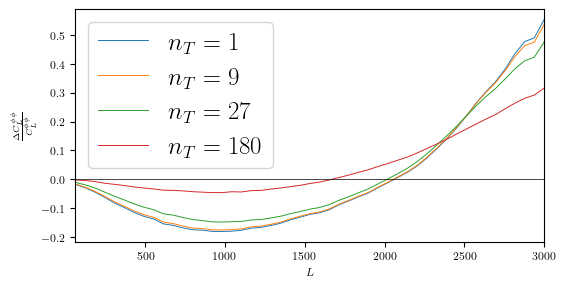

In [11]:
Cls = np.interp(experiment.biases['ells'], experiment.cl_unl.ls, experiment.cl_unl.clpp)

for experiment in exp_list:
    plt.plot(experiment.biases['ells'], experiment.biases['tsz']['prim_bispec']['1h']/Cls, label=r'$n_T$ = {}'.format(int(experiment.nlev_t)))

plt.xlim([60,3000])
plt.axhline(0, color='k', ls='-', lw=0.5)
plt.xlabel(r'$L$')
plt.ylabel(r'$\frac{\Delta C_L^{\phi\phi}}{C_L^{\phi\phi}}$')
plt.legend()



# In cross-correlation with a galaxy sample

In [6]:
# You can specify a cosmological model -- in this case, match Websky
H0 = 68.
cosmoParams = {'As':2.08e-9,'ns':.965,'omch2':(0.31-0.049)*(H0/100.)**2,'ombh2':0.049*(H0/100.)**2,'tau':0.055,'H0':H0}

z_max = 2.5 #3
nZs = 40 #50
nMasses = 40  #30
Mmin = 1e10 #Keep this low -- the 2h term of the bispectrum bias can be sensitive to quite low-mass halos

# Set CIB halo model
cib_model='planck13'#'vierro'

# Initialise a halo model object for the calculation, using mostly default parameters
hm_calc = biases.hm_framework(cosmoParams=cosmoParams, m_min=Mmin, nZs=nZs, nMasses=nMasses, cib_model=cib_model, z_max=z_max)

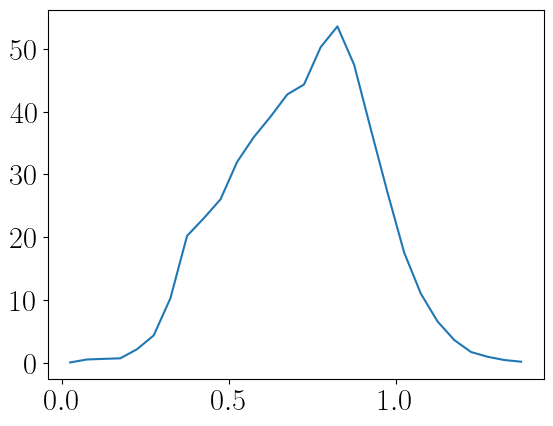

In [7]:
from cosmoblender import tools as tls
survey_name = "DESI LRG"

# Add the HOD for the galaxy sample that we will be cross-correlating with CMB lensing
z_mean_gal, surface_ngal_of_z_gal = tls.get_DESI_surface_ngal_of_z('lrg')
plt.plot(z_mean_gal, surface_ngal_of_z_gal)

# Assume a sample that's 100% complete above a stellar mass threshold of 10^11.5 Msun
hm_calc.hcos.add_hod(name=survey_name, mthresh=10**11.5+hm_calc.hcos.zs*0.) 

# Calculate the signal clkg
pgm_1h = hm_calc.hcos.get_power_1halo("nfw", survey_name)
pgm_2h = hm_calc.hcos.get_power_2halo("nfw", survey_name)
Pgm = pgm_1h + pgm_2h
ells = np.linspace(2, hm_calc.lmax_out, 50)
Cls = hm_calc.hcos.C_kg(ells, hm_calc.hcos.zs, hm_calc.hcos.ks, Pgm, gzs=z_mean_gal, gdndz=surface_ngal_of_z_gal, lzs=1100.)

In [ ]:
noise_arr = [0, 1e-1, 1, 10, 100]
exp_list = []
for noise in noise_arr:
    exp_properties = {'nlev_t': np.array([noise]),
                    'beam_size':np.array([0.]),
                    'freq_GHz': np.array([143.])}

    # Initialise experiments with various different mass cuts
    experiment = qest.experiment(lmax = 3000, massCut_Mvir=5e15, **exp_properties, **fg_cleaning_dict)

    if which_bias=='total' or which_bias=='tsz':
        hm_calc.get_tsz_cross_biases(experiment, z_mean_gal, surface_ngal_of_z_gal, survey_name=survey_name)
    
    exp_list.append(experiment)

The same story is true for all lmaxs: lowering the noise level below 10 muK does not change the zero crossing any further

In [ ]:
lmax_arr = [2500, 3000, 3500, 4000, 4500]
exp_properties = {'nlev_t': np.array([1.]),
                    'beam_size':np.array([0.]),
                    'freq_GHz': np.array([143.])}

exp_varyinglmax_list = []
for lmax in lmax_arr:
    # Initialise experiments with various different mass cuts

    # Initialise experiments with various different mass cuts
    experiment = qest.experiment(lmax = lmax, massCut_Mvir=5e15, **exp_properties, **fg_cleaning_dict)

    if which_bias=='total' or which_bias=='tsz':
        hm_calc.get_tsz_cross_biases(experiment, z_mean_gal, surface_ngal_of_z_gal, survey_name=survey_name)
    
    exp_varyinglmax_list.append(experiment)

In [ ]:
Mcuts = [1e14, 2e14, 5e14, 1e15, 5e15]

exps_varying_Mcut = []
for Mcut in Mcuts:
    # Initialise a halo model object for the calculation, using mostly default parameters
    hm_calc = biases.hm_framework(cosmoParams=cosmoParams, m_min=Mmin, nZs=nZs, nMasses=nMasses, cib_model=cib_model, z_max=z_max)

    # Assume a sample that's 100% complete above a stellar mass threshold of 10^11.5 Msun
    hm_calc.hcos.add_hod(name=survey_name, mthresh=10**11.5+hm_calc.hcos.zs*0.)
    # Initialise experiments with various different mass cuts
    experiment = qest.experiment(lmax = 3000, massCut_Mvir=Mcut, **exp_properties, **fg_cleaning_dict)

    if which_bias=='total' or which_bias=='tsz':
        hm_calc.get_tsz_cross_biases(experiment, z_mean_gal, surface_ngal_of_z_gal, survey_name=survey_name)
    
    exps_varying_Mcut.append(experiment)

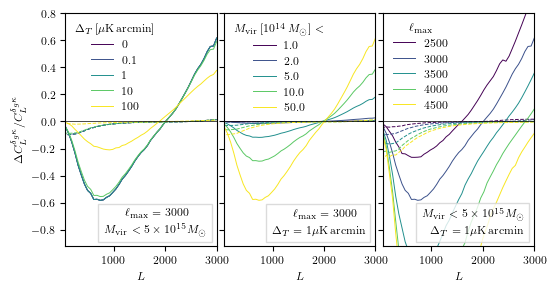

In [ ]:
ells_rescaling = 0.5 * experiment.biases['ells']*(experiment.biases['ells']+1)

fig, axes = plt.subplots(1, 3, sharex=True, sharey=True, figsize=(textwidth, textheight), squeeze=True)

i=0
for ax, exps, title in zip(axes, [exp_list, exps_varying_Mcut, exp_varyinglmax_list], [r'$\Delta_T\,[\mu\mathrm{K}\,\mathrm{arcmin}]$', r'$M_{\rm vir}$\,[$10^{14}\,M_{\odot}$] $<$ ', r'$\ell_{\rm max}$']):
    colors = cm.viridis(np.linspace(0, 0.99, len(exp_list)))
    if i==0:
        labels = noise_arr
    elif i==1:
        labels = np.array(Mcuts)/1e14
    elif i==2:
        labels = lmax_arr
    j=0
    for experiment, color in zip(exps, colors):
        ax.plot(experiment.biases['ells'], ells_rescaling*experiment.biases['tsz']['cross_w_gals']['1h']/Cls, color=color, ls='-', label=labels[j])
        ax.plot(experiment.biases['ells'], ells_rescaling*experiment.biases['tsz']['cross_w_gals']['2h']/Cls, color=color, ls='--')
        j+=1
    ax.legend(loc='upper left', title=title, fontsize=8, frameon=False)
    ax.axhline(0, color='k', ls='-', lw=0.5)
    ax.set_xlabel(r'$L$')
    i+=1

# Make an annotation in the lower center of each panel, putting it inside a box
for ax, label in zip(axes, [r'$ \ell_{\mathrm{max}}=3000$\\$M_{\rm vir}<5\times 10^{15}M_{\odot}$', r'$\ell_{\mathrm{max}}=3000$\\$\Delta_T = 1\mu\mathrm{K}\,\mathrm{arcmin}$', r'$M_{\rm vir}<5\times 10^{15}M_{\odot}$\\$\hphantom{11111}\Delta_T = 1\mu\mathrm{K}\,\mathrm{arcmin}$']):
    ax.text(0.93, 0.1, label, ha='right', va='center'
            , transform=ax.transAxes
            , bbox=dict(facecolor='white', alpha=0.8, edgecolor='lightgrey'))


plt.subplots_adjust(hspace=0.05, wspace=0.05)

plt.xlim([60,3000])
plt.ylim([-0.92,0.8])

axes[0].set_ylabel(r'$\Delta C_{L}^{\delta_{g}\kappa}/C_{L}^{\delta_{g}\kappa}$')

plt.savefig(plots_dir+'zero_crossing_prim_bispec_tszonly.pdf', bbox_inches='tight', dpi=1000)
